In [1]:
import os
import pickle
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import scripts.helper_funcs as funcs
from scripts.utils import path_to_load, path_to_save

In [2]:
# Load the data
with open(os.path.join(path_to_save, 'trajectory_prediction_multi-step.pkl'), 'rb') as f:
    results = pickle.load(f)

# Unpack
errors = results['errors']
errors_train = results['errors_train']
linear_errors = results['linear_errors']
pred_future = results['predictions']
true_future = results['true_future']
true_past = results['true_past']
target_id = results['trajectory_vars']['target_id']
losses = results['losses']
trajectory_vars = results['trajectory_vars']

targ_file = 'targets_xy_positions_jazz.npy'
targXY = np.load(os.path.join(path_to_load, targ_file))
targ_x, targ_y = targXY

In [3]:
mean_errors = errors.mean(axis=1) # (ntrials,)
errors_over_time = errors.mean(axis=0) # (n_future_time,)
mean_errors_train = errors_train.mean(axis=1)
errors_over_time_train = errors_train.mean(axis=0)
mean_linear_errors = linear_errors.mean(axis=1)
linear_errors_over_time = linear_errors.mean(axis=0)

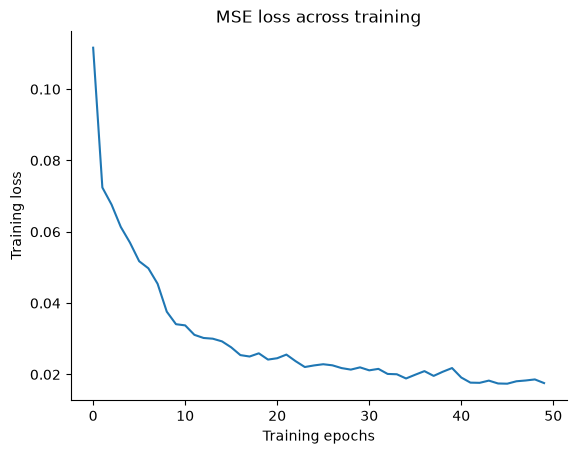

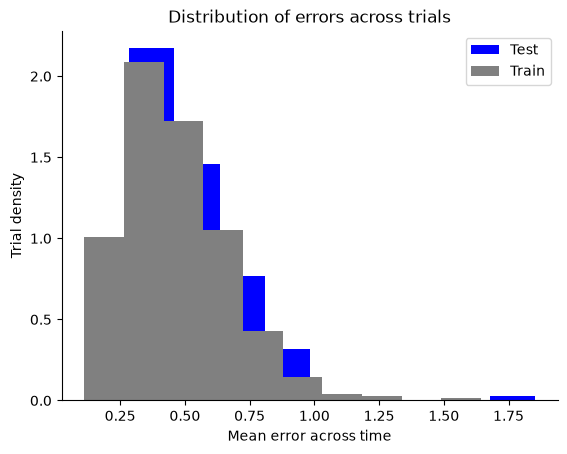

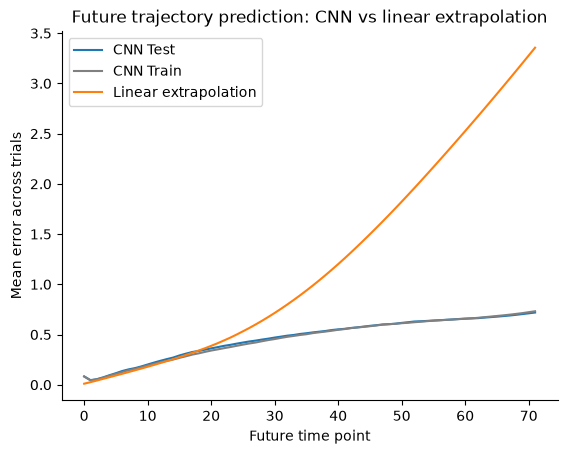

In [4]:
# Plot training losses
plt.figure()
plt.plot(losses)
plt.xlabel('Training epochs')
plt.ylabel('Training loss')
plt.gca().spines[['right','top']].set_visible(False)
plt.title('MSE loss across training')

# Quantify train/test performance and linear extrapolation errors
plt.figure()
plt.hist(mean_errors, density=True, color='b', label='Test')
plt.hist(mean_errors_train, density=True, color='grey', label='Train')
plt.gca().spines[['right','top']].set_visible(False)
plt.xlabel('Mean error across time')
plt.ylabel('Trial density')
plt.title('Distribution of errors across trials')
plt.legend()

plt.figure()
plt.plot(errors_over_time, label='CNN Test')
plt.plot(errors_over_time_train, color='grey', label='CNN Train')
plt.plot(linear_errors_over_time, label='Linear extrapolation')
plt.gca().spines[['right','top']].set_visible(False)
plt.xlabel('Future time point')
plt.ylabel('Mean error across trials')
plt.title('Future trajectory prediction: CNN vs linear extrapolation')
plt.legend()

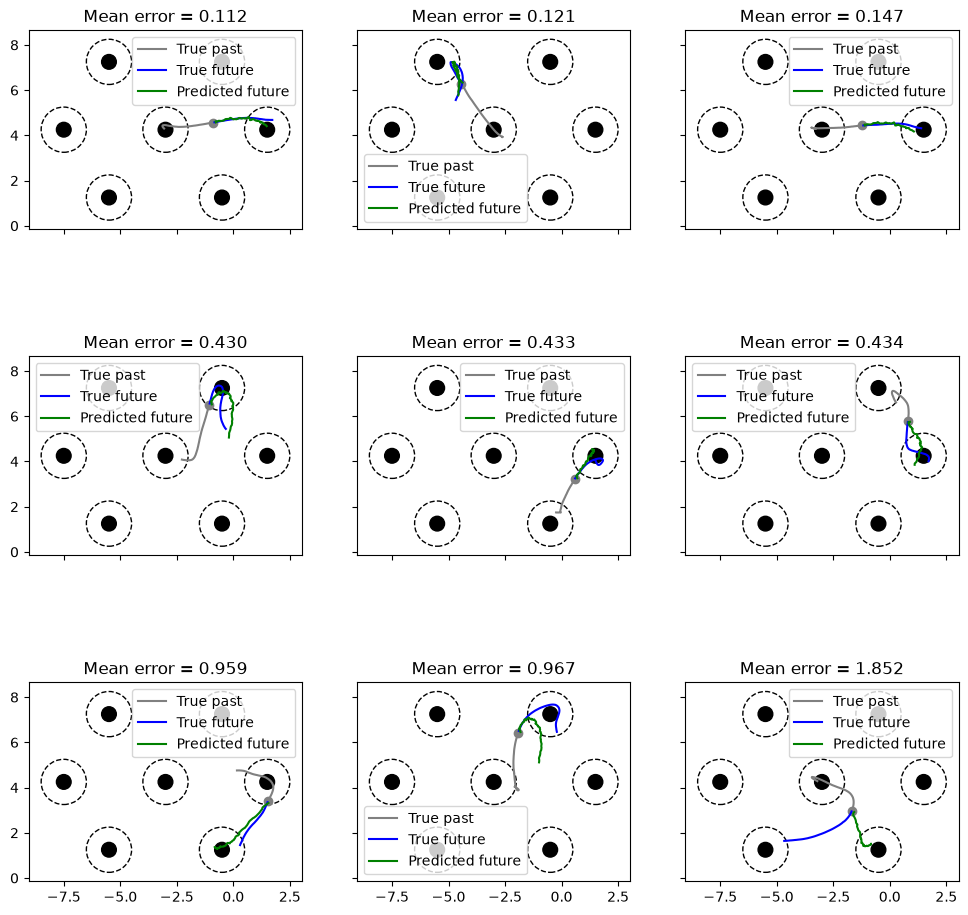

In [4]:
# Plot examples of best, median, worst trajectories (observed past, predicted future and true future)
sorted_inds = np.argsort(mean_errors)
m = sorted_inds.size//2
trial_inds = np.concatenate((sorted_inds[:3], sorted_inds[m-2:m+1], sorted_inds[-3:]))

f,axes = plt.subplots(3, 3, sharex=True, sharey=True, figsize=(12,12))
axes = axes.flatten()
for a,trial in enumerate(trial_inds):
    funcs.plot_trajectory(axes[a], trial, true_past, true_future, pred_future, 
                            targ_x, targ_y, mean_errors)
plt.savefig(os.path.join(path_to_save,'predicted_trajectories.svg'))

                            OLS Regression Results                            
Dep. Variable:             mean_error   R-squared:                       0.063
Model:                            OLS   Adj. R-squared:                  0.032
Method:                 Least Squares   F-statistic:                     2.020
Date:                Mon, 26 Oct 2026   Prob (F-statistic):             0.0540
Time:                        12:49:34   Log-Likelihood:                 35.461
No. Observations:                 217   AIC:                            -54.92
Df Residuals:                     209   BIC:                            -27.88
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.4654      0.106      4.396   

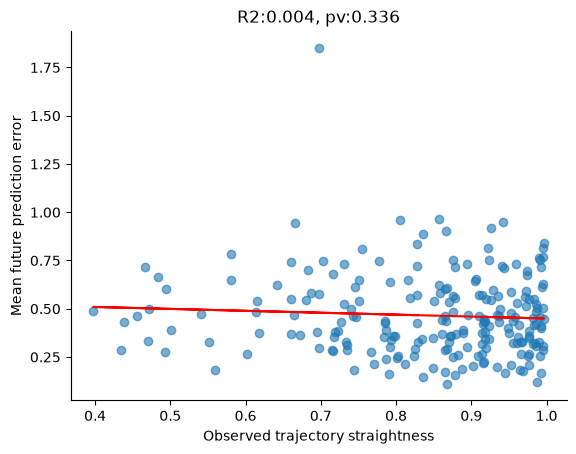

In [6]:
# Regression of errors against straigthness
trajectory_vars.update({'mean_error': mean_errors})
df = pd.DataFrame(trajectory_vars)
x = df['straightness']
y = df['mean_error']
ols = sm.OLS(y, sm.add_constant(x)).fit()
r2 = ols.rsquared
pv = ols.pvalues.straightness
slope = ols.params.straightness
intercept = ols.params.const

plt.figure()
plt.scatter(x, y, alpha=0.6)
plt.plot(x, slope*x + intercept, color='r')
plt.xlabel(f'Observed trajectory straightness')
plt.ylabel('Mean future prediction error')
plt.title(f'R2:{r2:.3f}, pv:{pv:.3f}')
plt.gca().spines[['right','top']].set_visible(False)

# Multiple regression of errors against straigthness, path length, target id
x = df[['straightness','path_length','target_id']]
X = pd.get_dummies(x, columns=['target_id'], drop_first=True)
y = df['mean_error']
ols_multi = sm.OLS(y, sm.add_constant(X)).fit()
print(ols_multi.summary())